# Café Sales: Cleaning and Exploratory Data Analysis

**The question:** a café handed over a year of point-of-sale data (10,000 transactions from 2023). Before anyone can trust a single number from it, the data has to be cleaned. Once it is clean, what does it actually say about the business?

**What's in this notebook**
1. Data quality audit: what's broken and how badly
2. Cleaning: rebuilding missing values with logic instead of guesses
3. Exploratory analysis: products, time, order size, payment and location
4. Statistical checks on the differences I see
5. Findings, recommendations and limitations

**Data:** [Cafe Sales - Dirty Data for Cleaning Training](https://www.kaggle.com/datasets/ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training) on Kaggle.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

sys.path.append("../src")
from cleaning import BAD_TOKENS, LINKED, load_raw, to_missing_and_typed, learn_menu, fill_linked_columns

# One consistent look for every chart: one accent color, gray for context, light grid
ACCENT, GRAY, INK, MUTED = "#2a78d6", "#b4b2a9", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10.5,
})
IMG = "../images/"
def save(name):
    plt.tight_layout()
    plt.savefig(IMG + name, bbox_inches="tight", dpi=150)
    plt.show()

RAW_PATH = "../data/raw/dirty_cafe_sales.csv"

## 1. First look

I load every column as **text** and turn off pandas' automatic missing-value handling. That way I see the bad values exactly as they appear in the file, instead of pandas quietly deciding for me.

In [2]:
raw = load_raw(RAW_PATH)
print(raw.shape)
raw.head()

(10000, 8)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              10000 non-null  str  
 2   Quantity          10000 non-null  str  
 3   Price Per Unit    10000 non-null  str  
 4   Total Spent       10000 non-null  str  
 5   Payment Method    10000 non-null  str  
 6   Location          10000 non-null  str  
 7   Transaction Date  10000 non-null  str  
dtypes: str(8)
memory usage: 625.1 KB


Quantity, price, total and date are all stored as text. That usually means something non-numeric is hiding in those columns. Looking at the most common values in each column shows what it is:

In [4]:
for col in raw.columns[1:]:
    counts = raw[col].value_counts()
    if col in ["Quantity", "Price Per Unit", "Total Spent", "Transaction Date"]:
        shown = counts[~counts.index.str.match(r"^[\d.\-]+$")]   # anything that isn't a number or date
        print(f"{col:<17} non-numeric values: {shown.to_dict()}")
    else:
        print(f"{col:<17} all values: {counts.to_dict()}")

Item              all values: {'Juice': 1171, 'Coffee': 1165, 'Salad': 1148, 'Cake': 1139, 'Sandwich': 1131, 'Smoothie': 1096, 'Cookie': 1092, 'Tea': 1089, 'UNKNOWN': 344, '': 333, 'ERROR': 292}
Quantity          non-numeric values: {'UNKNOWN': 171, 'ERROR': 170, '': 138}
Price Per Unit    non-numeric values: {'ERROR': 190, '': 179, 'UNKNOWN': 164}
Total Spent       non-numeric values: {'': 173, 'UNKNOWN': 165, 'ERROR': 164}
Payment Method    all values: {'': 2579, 'Digital Wallet': 2291, 'Credit Card': 2273, 'Cash': 2258, 'ERROR': 306, 'UNKNOWN': 293}
Location          all values: {'': 3265, 'Takeaway': 3022, 'In-store': 3017, 'ERROR': 358, 'UNKNOWN': 338}
Transaction Date  non-numeric values: {'': 159, 'UNKNOWN': 159, 'ERROR': 142}


Three tokens mean "no data": an empty string, `ERROR` and `UNKNOWN`. Item names, payment methods and locations are otherwise clean (no typos or casing problems), so these three tokens are the whole problem.

## 2. Data quality audit

In [5]:
cols = raw.columns[1:]
bad = raw[cols].isin(BAD_TOKENS)
rows_with_problem = bad.any(axis=1).sum()
print(f"Rows with at least one bad value: {rows_with_problem:,} of {len(raw):,} ({rows_with_problem / len(raw):.0%})")

audit = pd.DataFrame({tok if tok else "(blank)": (raw[cols] == tok).sum() for tok in BAD_TOKENS})
audit["total"] = audit.sum(axis=1)
audit["% of rows"] = (audit["total"] / len(raw) * 100).round(1)
audit.sort_values("total", ascending=False)

Rows with at least one bad value: 6,911 of 10,000 (69%)


,(blank),ERROR,UNKNOWN,total,% of rows
Location,3265,358,338,3961,39.6
Payment Method,2579,306,293,3178,31.8
Item,333,292,344,969,9.7
Price Per Unit,179,190,164,533,5.3
Total Spent,173,164,165,502,5.0
Quantity,138,170,171,479,4.8
Transaction Date,159,142,159,460,4.6


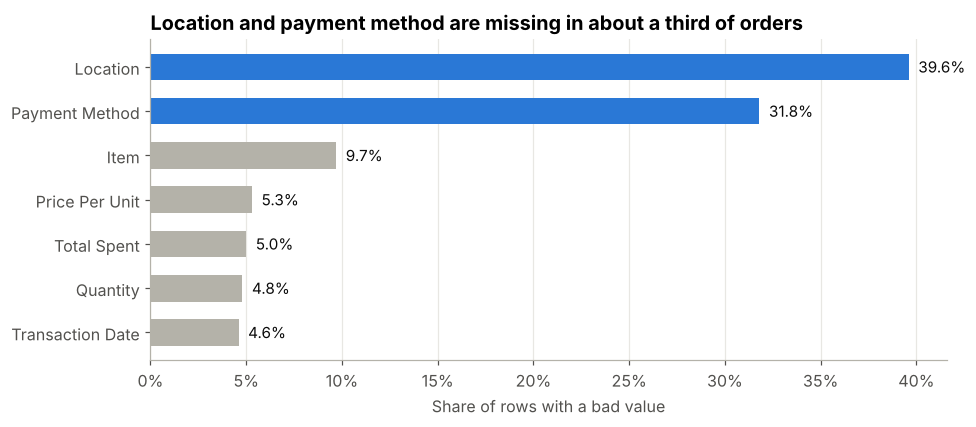

In [6]:
pct = audit["% of rows"].sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
colors = [ACCENT if v > 20 else GRAY for v in pct]
ax.barh(pct.index, pct.values, color=colors, height=0.6)
for y, v in enumerate(pct.values):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", color=INK, fontsize=10)
ax.set_title("Location and payment method are missing in about a third of orders")
ax.set_xlabel("Share of rows with a bad value")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="y", visible=False)
save("01_missing_by_column.png")

**69% of rows have at least one problem**, so dropping bad rows would throw away most of the data. That's not an option. Two kinds of damage need different treatment:

- **Item, quantity, price, total (5 to 10% missing each):** these four columns are linked by math, so many gaps can be rebuilt.
- **Payment method and location (32 to 40% missing):** nothing else in the row tells me these, so they can't be rebuilt.

Before cleaning, one more question: are the gaps random, or do they hide something? If, say, takeaway orders were the ones losing their location, any location comparison would be biased.

In [7]:
df = to_missing_and_typed(raw)

# Do orders with a missing location spend differently from orders with one?
loc_missing = df["Location"].isna()
print("Average total, location missing vs present:")
print(df.groupby(loc_missing)["Total Spent"].mean().round(2).rename({True: "missing", False: "present"}))

# If gaps are independent, both-missing should happen about P(a) x P(b) x N times
both = (df["Location"].isna() & df["Payment Method"].isna()).sum()
expected = df["Location"].isna().mean() * df["Payment Method"].isna().mean() * len(df)
print(f"\nLocation AND payment both missing: {both:,} rows (about {expected:,.0f} expected if independent)")

Average total, location missing vs present:
Location
present    8.91
missing    8.95
Name: Total Spent, dtype: float64

Location AND payment both missing: 1,294 rows (about 1,259 expected if independent)


Orders with and without a location spend the same, and the two gaps overlap about as often as chance predicts. The missingness looks **random**, which means the rows that do have a location or payment method are a fair sample to compare.

## 3. Cleaning

### 3.1 Prove the menu has fixed prices
The key to rebuilding data is one assumption: **each item always sells at one price.** I check it in code before relying on it.

In [8]:
known = df.dropna(subset=["Item", "Price Per Unit"])
print("Distinct prices per item:", known.groupby("Item")["Price Per Unit"].nunique().to_dict())

menu = learn_menu(df)   # raises an error if any item had two prices
menu

Distinct prices per item: {'Cake': 1, 'Coffee': 1, 'Cookie': 1, 'Juice': 1, 'Salad': 1, 'Sandwich': 1, 'Smoothie': 1, 'Tea': 1}


{'Cake': 3.0,
 'Coffee': 2.0,
 'Cookie': 1.0,
 'Juice': 3.0,
 'Salad': 5.0,
 'Sandwich': 4.0,
 'Smoothie': 4.0,
 'Tea': 1.5}

In [9]:
# Also confirm Total = Quantity x Price wherever all three exist
full = df.dropna(subset=["Quantity", "Price Per Unit", "Total Spent"])
mismatch = (full["Quantity"] * full["Price Per Unit"] - full["Total Spent"]).abs() > 0.001
print(f"Rows where total != quantity x price: {mismatch.sum()} of {len(full):,}")

Rows where total != quantity x price: 0 of 8,544


Both rules hold with zero exceptions. That gives me five safe fill rules:

| If this is missing | and I know | then |
|---|---|---|
| Price | Item | price from the menu |
| Price | Total and quantity | total ÷ quantity |
| Item | A price only one item has (e.g. 5.0 is only Salad) | the item |
| Quantity | Total and price | total ÷ price |
| Total | Quantity and price | quantity × price |

Cake and Juice both cost 3.0, and Sandwich and Smoothie both cost 4.0. So for those prices I **don't** guess the item. One fix can unlock another (finding a price lets me compute a total), so the rules run in a few passes.

In [10]:
before = df[LINKED].isna().sum()
clean = fill_linked_columns(df, menu)
after = clean[LINKED].isna().sum()

recovery = pd.DataFrame({"missing before": before, "still missing": after})
recovery["recovered"] = recovery["missing before"] - recovery["still missing"]
recovery["% recovered"] = (recovery["recovered"] / recovery["missing before"] * 100).round(1)
recovery

,missing before,still missing,recovered,% recovered
Item,969,480,489,50.5
Quantity,479,23,456,95.2
Price Per Unit,533,6,527,98.9
Total Spent,502,23,479,95.4


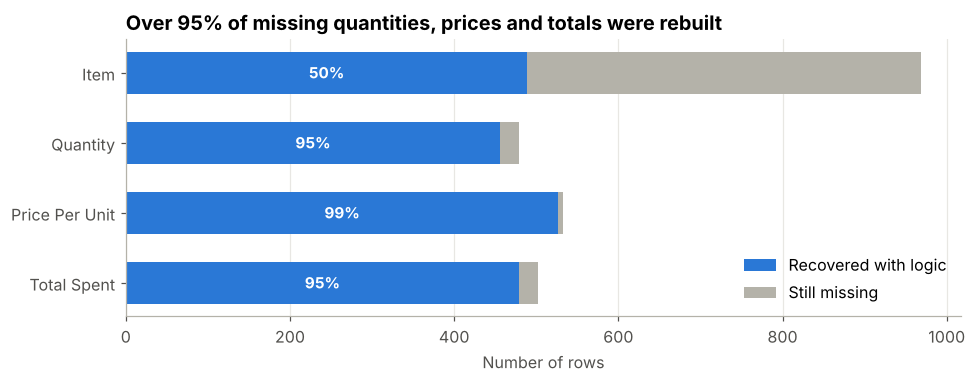

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
r = recovery.iloc[::-1]
ax.barh(r.index, r["recovered"], color=ACCENT, height=0.6, label="Recovered with logic")
ax.barh(r.index, r["still missing"], left=r["recovered"], color=GRAY, height=0.6, label="Still missing")
for y, (rec, pctv) in enumerate(zip(r["recovered"], r["% recovered"])):
    ax.text(rec / 2, y, f"{pctv:.0f}%", va="center", ha="center", color="white", fontsize=10, fontweight="bold")
ax.set_title("Over 95% of missing quantities, prices and totals were rebuilt")
ax.set_xlabel("Number of rows")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
save("02_recovery.png")

Item recovers least (about half), because many missing items sit next to a shared price like 3.0 or 4.0. Leaving those as missing is the honest choice.

### 3.2 Decisions on what's left
- **Payment method and location:** I label them `Not recorded` instead of dropping rows. Revenue analysis keeps every order, and the comparisons between payment types or locations use only the rows where it was recorded (fine, since the gaps are random).
- **Date (4.6% missing):** left missing. Those orders count toward revenue totals but not toward time trends.
- **Total still missing (23 rows):** excluded from revenue. That's 0.2% of rows.

In [12]:
for col in ["Payment Method", "Location"]:
    clean[col] = clean[col].fillna("Not recorded")

sales = clean.dropna(subset=["Total Spent"]).copy()
dated = sales.dropna(subset=["Transaction Date"]).copy()
dated["month"] = dated["Transaction Date"].dt.to_period("M")
dated["weekday"] = dated["Transaction Date"].dt.day_name()

print(f"Usable orders for revenue: {len(sales):,} of {len(raw):,} ({len(sales)/len(raw):.1%})")
print(f"Total revenue: ${sales['Total Spent'].sum():,.2f}")
print(f"Revenue counted before cleaning: ${df['Total Spent'].sum():,.2f}  ->  ${sales['Total Spent'].sum() - df['Total Spent'].sum():,.2f} recovered")

clean.to_csv("../data/processed/cafe_sales_clean.csv", index=False)

Usable orders for revenue: 9,977 of 10,000 (99.8%)
Total revenue: $89,096.00
Revenue counted before cleaning: $84,763.50  ->  $4,332.50 recovered


Cleaning brought **99.8% of orders** back into the revenue numbers, and recovered about $4,300 that a naive sum would have missed.

## 4. Exploratory analysis

### 4.1 Order size: what does a typical order look like?

In [13]:
sales["Total Spent"].describe().round(2)

count    9977.00
mean        8.93
std         6.00
min         1.00
25%         4.00
50%         8.00
75%        12.00
max        25.00
Name: Total Spent, dtype: float64

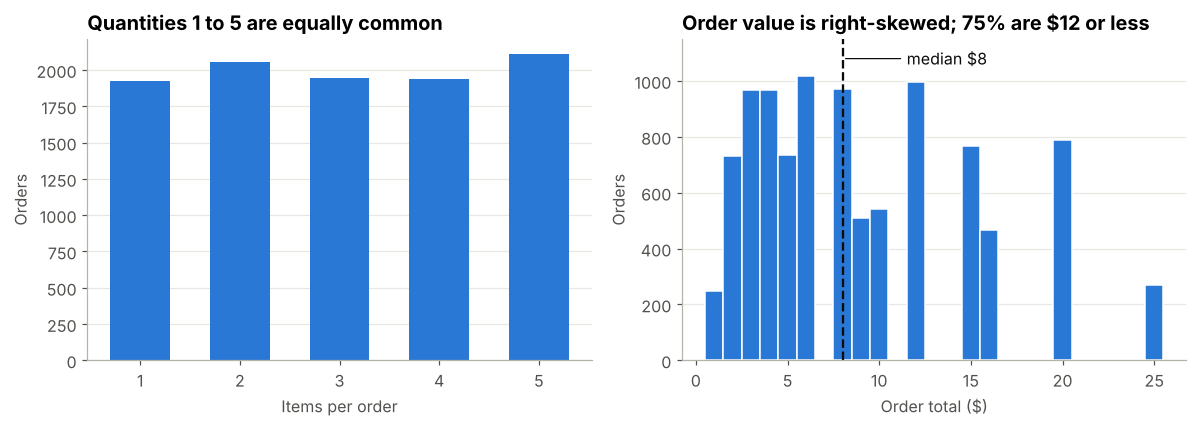

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
q = sales["Quantity"].value_counts().sort_index()
axes[0].bar(q.index.astype(int), q.values, color=ACCENT, width=0.6)
axes[0].set_title("Quantities 1 to 5 are equally common")
axes[0].set_xlabel("Items per order"); axes[0].set_ylabel("Orders")
axes[0].grid(axis="x", visible=False)

axes[1].hist(sales["Total Spent"], bins=np.arange(0.5, 26.5, 1), color=ACCENT, edgecolor="white")
med = sales["Total Spent"].median()
axes[1].axvline(med, color=INK, lw=1.5, ls="--")
axes[1].annotate(f"median ${med:.0f}", xy=(med, 1080), xytext=(med + 3.5, 1080), color=INK, va="center",
                 arrowprops=dict(arrowstyle="-", color=INK, lw=0.8))
axes[1].set_ylim(0, 1150)
axes[1].set_title("Order value is right-skewed; 75% are $12 or less")
axes[1].set_xlabel("Order total ($)"); axes[1].set_ylabel("Orders")
axes[1].grid(axis="x", visible=False)
save("03_order_size.png")

The median order is **$8** and three in four orders are $12 or less. Large orders ($20+) only happen when someone buys 4 or 5 of the pricier items.

### 4.2 Products: popularity vs revenue

In [15]:
by_item = sales.dropna(subset=["Item"]).groupby("Item").agg(
    orders=("Transaction ID", "count"), units=("Quantity", "sum"), revenue=("Total Spent", "sum"))
by_item["price"] = pd.Series(menu)
by_item["revenue share %"] = (by_item["revenue"] / by_item["revenue"].sum() * 100).round(1)
by_item.sort_values("revenue", ascending=False)

,orders,units,revenue,price,revenue share %
Item,,,,,
Salad,1270,3819.0,19095.0,5.0,22.7
Sandwich,1127,3429.0,13716.0,4.0,16.3
Smoothie,1094,3336.0,13344.0,4.0,15.9
Juice,1168,3505.0,10515.0,3.0,12.5
Cake,1138,3468.0,10404.0,3.0,12.4
Coffee,1286,3904.0,7808.0,2.0,9.3
Tea,1206,3650.0,5475.0,1.5,6.5
Cookie,1211,3598.0,3598.0,1.0,4.3


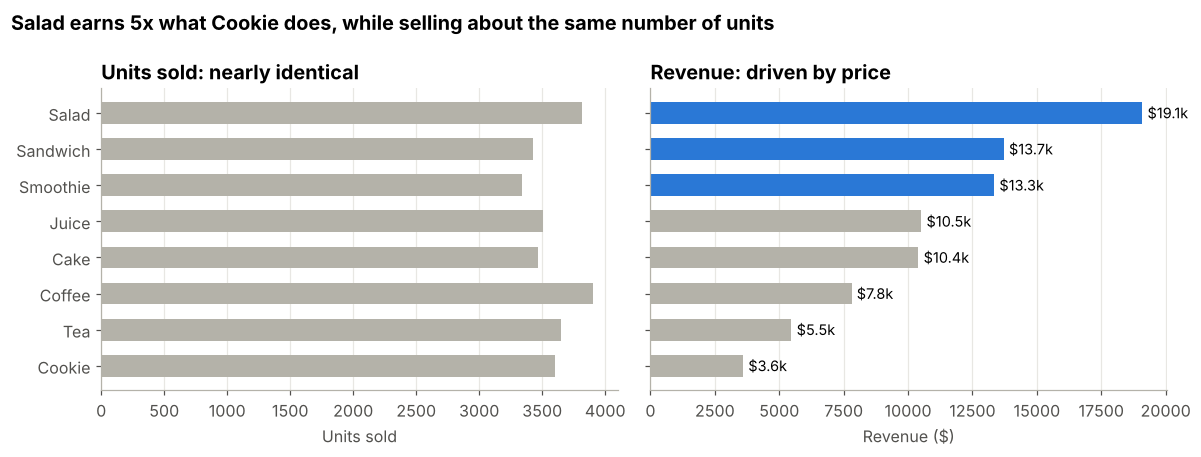

In [16]:
order = by_item.sort_values("revenue").index
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
top3 = by_item["revenue"].nlargest(3).index
axes[0].barh(order, by_item.loc[order, "units"], color=GRAY, height=0.6)
axes[0].set_title("Units sold: nearly identical")
axes[0].set_xlabel("Units sold")
axes[1].barh(order, by_item.loc[order, "revenue"], height=0.6,
             color=[ACCENT if i in top3 else GRAY for i in order])
for y, i in enumerate(order):
    axes[1].text(by_item.loc[i, "revenue"] + 200, y, f"${by_item.loc[i, 'revenue']/1000:.1f}k", va="center", fontsize=9.5)
axes[1].set_title("Revenue: driven by price")
axes[1].set_xlabel("Revenue ($)")
for a in axes: a.grid(axis="y", visible=False)
fig.suptitle("Salad earns 5x what Cookie does, while selling about the same number of units", x=0.01, ha="left", fontweight="bold", fontsize=13)
save("04_items.png")

In [17]:
r, p = stats.pearsonr(by_item["price"], by_item["revenue"])
print(f"Correlation between menu price and item revenue: r = {r:.2f} (p = {p:.4f})")
print(f"Top 3 items (Salad, Sandwich, Smoothie) = {by_item['revenue'].nlargest(3).sum() / by_item['revenue'].sum():.0%} of item revenue")

Correlation between menu price and item revenue: r = 0.99 (p = 0.0000)
Top 3 items (Salad, Sandwich, Smoothie) = 55% of item revenue


This is the most useful finding in the data. **Customers buy every item in roughly equal amounts**, so revenue ranking is almost entirely a price ranking (r ≈ 0.99). Salad, Sandwich and Smoothie bring in 55% of the revenue. Cookie and Tea together bring in just over 10%.

### 4.3 Time: is there a busy season or a busy day?

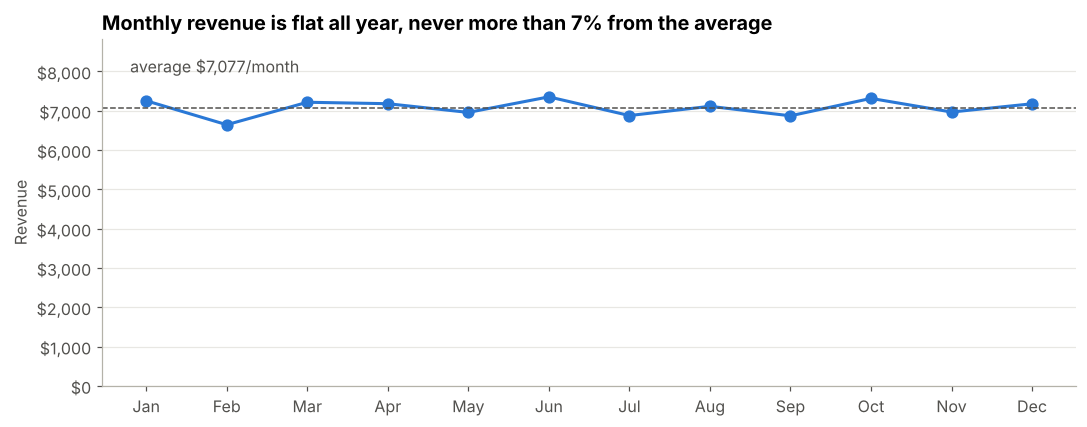

Lowest month $6,644, highest $7,353, coefficient of variation 3.0%


In [18]:
monthly = dated.groupby("month")["Total Spent"].agg(["sum", "count"])
mean_month = monthly["sum"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
x = monthly.index.strftime("%b")
ax.plot(x, monthly["sum"], color=ACCENT, lw=2, marker="o", ms=7)
ax.axhline(mean_month, color=MUTED, ls="--", lw=1)
ax.text(-0.2, mean_month + 900, f"average ${mean_month:,.0f}/month", color=MUTED, ha="left")
ax.set_ylim(0, monthly["sum"].max() * 1.2)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_title("Monthly revenue is flat all year, never more than 7% from the average")
ax.set_ylabel("Revenue")
ax.grid(axis="x", visible=False)
save("05_monthly.png")
print(f"Lowest month ${monthly['sum'].min():,.0f}, highest ${monthly['sum'].max():,.0f}, "
      f"coefficient of variation {monthly['sum'].std() / mean_month:.1%}")

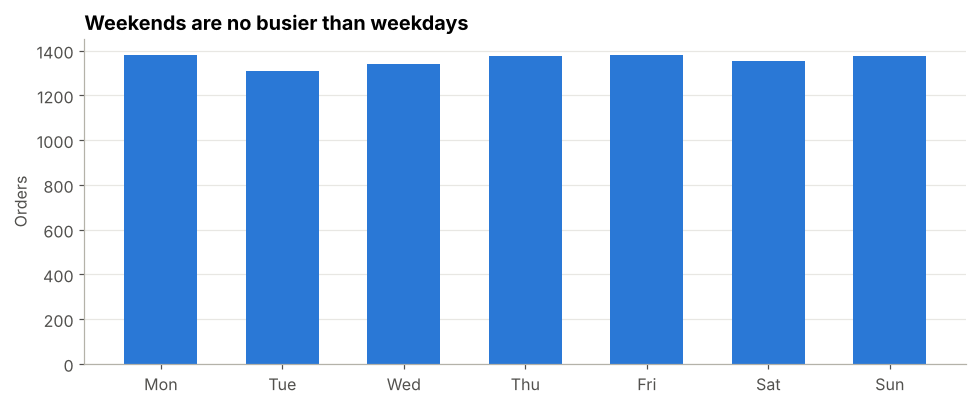

,sum,count,mean
weekday,,,
Monday,12140.0,1379,8.80
Tuesday,12039.5,1308,9.20
Wednesday,11680.5,1339,8.72
Thursday,12401.5,1376,9.01
Friday,12334.0,1383,8.92
Saturday,12039.5,1354,8.89
Sunday,12287.5,1378,8.92


In [19]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wk = dated.groupby("weekday")["Total Spent"].agg(["sum", "count", "mean"]).reindex(days)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([d[:3] for d in days], wk["count"], color=ACCENT, width=0.6)
ax.set_title("Weekends are no busier than weekdays")
ax.set_ylabel("Orders")
ax.grid(axis="x", visible=False)
save("06_weekday.png")
wk.round(2)

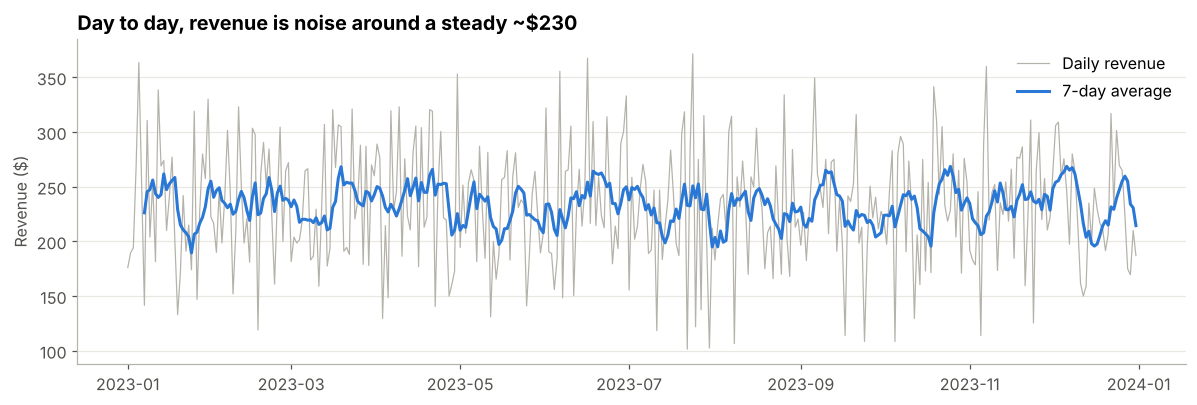

In [20]:
# Daily revenue with a 7-day rolling average, to look for any shorter-term pattern
daily = dated.groupby("Transaction Date")["Total Spent"].sum()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.index, daily.values, color=GRAY, lw=0.8, label="Daily revenue")
ax.plot(daily.index, daily.rolling(7).mean(), color=ACCENT, lw=2, label="7-day average")
ax.set_title("Day to day, revenue is noise around a steady ~$230")
ax.set_ylabel("Revenue ($)")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
save("07_daily.png")

No seasonality, no weekend effect, no trend. Every month lands between about $6,600 and $7,400. For a real café that's unusual (most see morning rushes, weekend peaks and seasonal drinks), and it's a hint about the data itself. I come back to this in the limitations.

### 4.4 Payment method and location

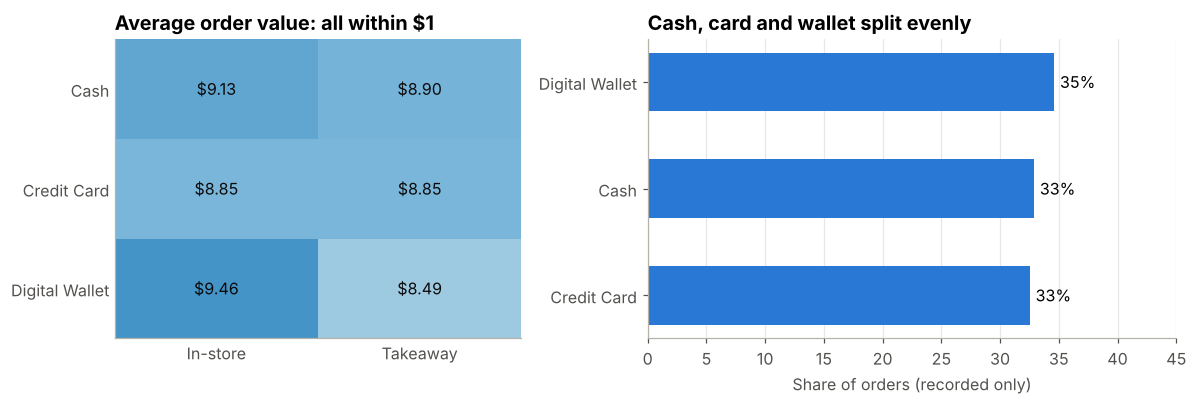

In [21]:
recorded = sales[(sales["Location"] != "Not recorded") & (sales["Payment Method"] != "Not recorded")]
mix = pd.crosstab(recorded["Payment Method"], recorded["Location"], normalize="index") * 100
aov = recorded.pivot_table(index="Payment Method", columns="Location", values="Total Spent", aggfunc="mean")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
im = axes[0].imshow(aov.values, cmap="Blues", vmin=7, vmax=11, aspect="auto")
axes[0].set_xticks(range(len(aov.columns)), aov.columns); axes[0].set_yticks(range(len(aov.index)), aov.index)
for i in range(aov.shape[0]):
    for j in range(aov.shape[1]):
        axes[0].text(j, i, f"${aov.values[i, j]:.2f}", ha="center", va="center", color=INK)
axes[0].set_title("Average order value: all within $1")
axes[0].tick_params(length=0)
axes[0].grid(False)

share = recorded["Payment Method"].value_counts(normalize=True).sort_values() * 100
axes[1].barh(share.index, share.values, color=ACCENT, height=0.55)
for y, v in enumerate(share.values):
    axes[1].text(v + 0.5, y, f"{v:.0f}%", va="center")
axes[1].set_xlim(0, 45)
axes[1].set_title("Cash, card and wallet split evenly")
axes[1].set_xlabel("Share of orders (recorded only)")
axes[1].grid(axis="y", visible=False)
save("08_payment_location.png")

In [22]:
# Does the product mix differ between in-store and takeaway?
loc_mix = pd.crosstab(sales.dropna(subset=["Item"])["Item"], sales.dropna(subset=["Item"])["Location"])
loc_mix = loc_mix[["In-store", "Takeaway"]]
(loc_mix / loc_mix.sum() * 100).round(1).sort_values("In-store", ascending=False)

Location,In-store,Takeaway
Item,,
Salad,14.1,13.2
Cookie,12.9,14.0
Sandwich,12.8,11.9
Tea,12.8,12.8
Juice,12.6,11.8
Coffee,12.3,13.8
Cake,11.2,11.9
Smoothie,11.2,10.6
